***r in rglob stands for recursive. This means it will automatically dive into all subfolders (whether you have two folders, ten folders, or nested subfolders) and find every single file inside them.***

In [1]:
import os
import zipfile

!pip install -q gdown
import gdown
#https://drive.google.com/file/d/1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-/view?usp=drive_link
file_id = '1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-'
zip_path = 'Shop_DataSet.zip'
extract_path = './dataset'

# 3. Download the file from Google Drive
url = f'https://drive.google.com/uc?id={file_id}'
gdown.download(url, zip_path, quiet=False)

# 4. Extract the zip file
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipping complete!")

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=271f3824-2a82-49cd-9809-efb43c865e21
To: /kaggle/working/Shop_DataSet.zip
100%|██████████| 1.78G/1.78G [00:11<00:00, 151MB/s] 


Unzipping complete!


In [2]:
!pip install torch torchvision

In [2]:

from pathlib import Path

import cv2
import pandas as pd


VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}


def inspect_video(video_path):
    # metadata from one video file.
    cap = cv2.VideoCapture(str(video_path))

    try:
        if not cap.isOpened():
            return None

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        # Avoid division by zero
        duration = frame_count / fps if fps > 0 else None

        return {
            "video": video_path.name,
            "class": video_path.parent.name,
            "frame_count": frame_count,
            "fps": fps,
            "duration_seconds": duration,
            "width": width,
            "height": height,
        }
    finally:
        cap.release()

def explore_dataset(dataset_dir):
    #Build a metadata table for videoes
    dataset_dir = Path(dataset_dir)
    records = []

    for video_path in sorted(dataset_dir.rglob("*")):
        if video_path.suffix.lower() not in VIDEO_EXTENSIONS:
            continue

        metadata = inspect_video(video_path)

        if metadata is not None:
            metadata["path"] = str(video_path)
            records.append(metadata)

    columns = [
        "video", "class", "frame_count", "fps",
        "duration_seconds", "width", "height", "path"
    ]
    df = pd.DataFrame(records, columns=columns)

    if df.empty:
        print("No readable videos found. Check the dataset path.")
        return df

    print("\n Number of clips per class ")
    print(df["class"].value_counts())

    print("\nDuration distribution (seconds) ")
    print(
        df.groupby("class")["duration_seconds"]
        .describe()
        .round(2)
    )

    print("\n Frame resolution distribution ")
    print(
        df.assign(
            resolution=df["width"].astype(str)
            + "x" + df["height"].astype(str)
        )["resolution"].value_counts()
    )

    print("\n Frame count distribution")
    print(df.groupby("class")["frame_count"].describe().round(1))

    df.to_csv("video_metadata.csv", index=False)
    print("\nSaved metadata to video_metadata.csv")

    return df


# if __name__ == "__main__":
#     df = explore_dataset("dataset")
df=explore_dataset('/kaggle/working/dataset/Shop DataSet')
df.info()


 Number of clips per class 
class
non shop lifters    531
shop lifters        324
Name: count, dtype: int64

Duration distribution (seconds) 
                  count   mean   std  min   25%   50%   75%    max
class                                                             
non shop lifters  531.0  13.93  5.37  3.0  11.0  14.0  16.0  74.00
shop lifters      324.0  12.22  3.35  4.0  10.0  12.0  15.0  23.03

 Frame resolution distribution 
resolution
704x576    855
Name: count, dtype: int64

 Frame count distribution
                  count   mean    std    min    25%    50%    75%     max
class                                                                    
non shop lifters  531.0  347.8  134.2   75.0  275.0  348.0  400.0  1850.0
shop lifters      324.0  304.6   83.5  100.0  248.0  300.0  372.0   570.0

Saved metadata to video_metadata.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 855 entries, 0 to 854
Data columns (total 8 columns):
 #   Column            Non-Null Count  

In [4]:
df['fps'].value_counts()

fps
25.00    666
24.75    103
24.83     86
Name: count, dtype: int64

In [3]:
df.head(5)

,video,class,frame_count,fps,duration_seconds,width,height,path
0,shop_lifter_n_0.mp4,non shop lifters,450,25.0,18.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
1,shop_lifter_n_0_1.mp4,non shop lifters,450,25.0,18.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
2,shop_lifter_n_1.mp4,non shop lifters,450,25.0,18.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
3,shop_lifter_n_10.mp4,non shop lifters,475,25.0,19.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...
4,shop_lifter_n_100.mp4,non shop lifters,400,25.0,16.0,704,576,/kaggle/working/dataset/Shop DataSet/non shop ...


In [6]:
df.iloc[800]

video                                          videyyyyyyyyyss_41.mp4
class                                                    shop lifters
frame_count                                                       200
fps                                                              25.0
duration_seconds                                                  8.0
width                                                             704
height                                                            576
path                /kaggle/working/dataset/Shop DataSet/shop lift...
Name: 800, dtype: object

Clipping: divides a long video into shorter temporal segments.

Frame sampling: selects \(T\) frames from one segment to represent it.

Shoplifting occurs only briefly in a long recording	Use event-centered clips, plus representative normal clips

In [ ]:
import hashlib
import pandas as pd

def get_file_hash(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


def drop_exact_duplicates(df):
    df = df.copy()

    df["file_hash"] = df["path"].apply(get_file_hash)

    # Check whether identical files have conflicting labels
    label_counts = df.groupby("file_hash")["label"].nunique()
    conflicting_hashes = label_counts[label_counts > 1].index

    conflicts = df[df["file_hash"].isin(conflicting_hashes)].copy()

    # Keep the first copy of each file
    cleaned_df = df.drop_duplicates(
        subset="file_hash",
        keep="first"
    ).copy()

    return cleaned_df, conflicts


cleaned_df , con =drop_exact_duplicates(df)



In [5]:

import numpy as np


def uniform_sample_indices(total_frames, target_frames):

    if total_frames <= 0:
        raise ValueError("total_frames must be positive")

    if target_frames <= 0:
        raise ValueError("target_frames must be positive")

    if target_frames == 1:
        return np.array([total_frames // 2], dtype=np.int64)

    if total_frames >= target_frames:
        interval = (total_frames - 1) / (target_frames - 1)

        indices = np.rint(
            np.arange(target_frames) * interval
        ).astype(np.int64)

        return indices

    # >>>>>>>>>>>>>>>>>>>Short clips:
    # repeat the final frame to preserve the target length.
    indices = np.arange(total_frames, dtype=np.int64)

    padding = np.full(
        target_frames - total_frames,
        total_frames - 1,
        dtype=np.int64,
    )

    return np.concatenate([indices, padding])


In [7]:
import matplotlib.pyplot as plt


def plot_video_metadata(df):

    data = df.copy()

  #& (data["fps"] > 0
    data["fps"] = pd.to_numeric(data["fps"], errors="coerce")
    valid_fps = data.loc[data["fps"].notna()].copy()

    if valid_fps.empty:
         print("No valid FPS values found.")
    else:
        # Count how many videos use each FPS value.
         fps_counts = (
            valid_fps["fps"].round(0)
            .value_counts()
            .sort_index()
            .rename_axis("FPS")
            .rename("Number of videos")
        )

    print("\\n--- Video counts by FPS ---")
    print(fps_counts.to_string())

    plt.figure(figsize=(10, 5))
    fps_counts.plot(kind="bar")
    plt.title("Number of Videos by FPS")
    plt.xlabel("Frames per second (FPS)")
    plt.ylabel("Number of videos")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

        # Show FPS distribution by class.
    plt.figure(figsize=(9, 5))
    valid_fps.boxplot(column="fps", by="class", grid=False)
    plt.title("FPS Distribution by Class")
    plt.suptitle("")
    plt.xlabel("Video class")
    plt.ylabel("FPS")
    plt.tight_layout()
    plt.show()

\n--- Video counts by FPS ---
FPS
25.0    855


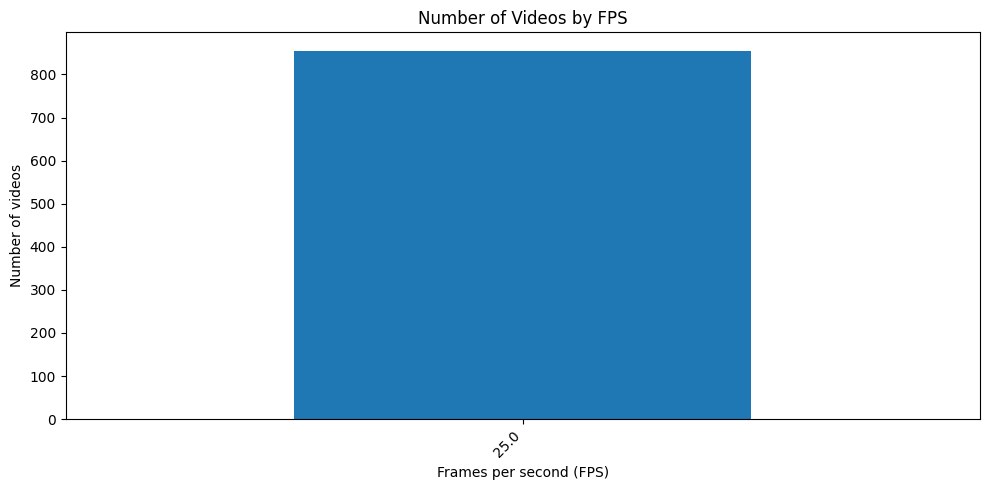

<Figure size 900x500 with 0 Axes>

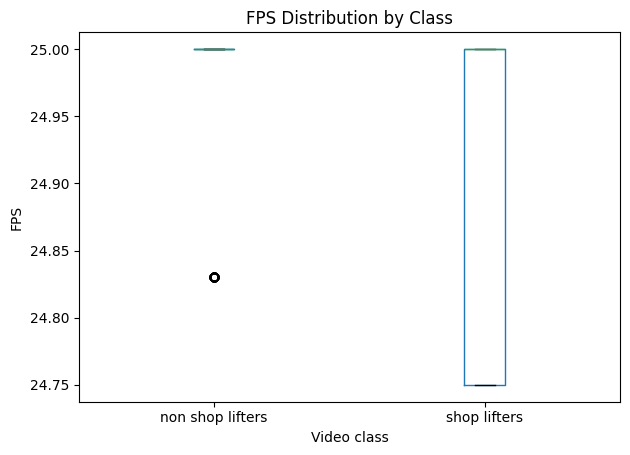

In [10]:
plot_video_metadata(df)

\n--- Class encoding ---
non shop lifters = 0, shop lifters = 1
class             label
non shop lifters  0        531
shop lifters      1        324
Name: video_count, dtype: int64


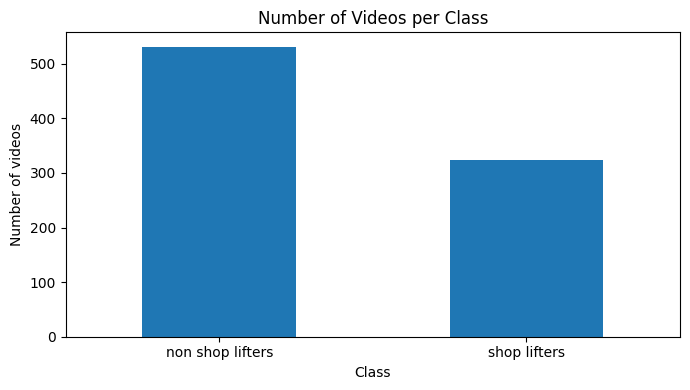

In [8]:
def encoding(df):
    class_to_idx = {"non shop lifters": 0, "shop lifters": 1}
    df["label"] = df["class"].str.strip().str.lower().map(class_to_idx)

    unknown = df.loc[df["label"].isna(), "class"].dropna().unique()
    if len(unknown):
        raise ValueError(
            f"Unknown class folder names: {unknown.tolist()}. "
            "Update class_to_idx to match your dataset."
        )

    df["label"] = df["label"].astype("int64")
    #df.drop(columns=["class"],inplace=True)

    print("\\n--- Class encoding ---")
    print("non shop lifters = 0, shop lifters = 1")
    print(df.groupby(["class", "label"]).size().rename("video_count"))
    # Save DataFrame to CSV
    df.to_csv("videos_dataset.csv", index=False)
    

    # Visualize class counts.
    class_counts = df["class"].value_counts().reindex(
        ["non shop lifters", "shop lifters"], fill_value=0
    )
    plt.figure(figsize=(7, 4))
    class_counts.plot(kind="bar")
    plt.title("Number of Videos per Class")
    plt.xlabel("Class")
    plt.ylabel("Number of videos")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()




encoding(df)
#df=df.drop(columns=["class"],inplace=True)

In [ ]:
df.to_csv("/kaggle/working/dataset/videos_dataset.csv", index=False)

In [9]:

import cv2
import numpy as np
from PIL import Image


def read_video_frames(video_path, num_frames=16):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError("Video contains no readable frames.")

    # Sample frames throughout the whole video.
    indices = np.linspace(
        0, total_frames - 1,
        num=num_frames
    ).round().astype(int)

    frames = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        success, frame = cap.read()

        if not success:
            cap.release()
            raise ValueError(f"Cannot read frame {idx}")

        # OpenCV BGR -> RGB.
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Your transform_video function expects PIL images.
        frames.append(Image.fromarray(frame))

    cap.release()
    return frames



Bilinear

Calculates a weighted average of nearby pixels. Produces smoother resized RGB frames and is a common choice for video classification.

In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(42)
CSV_PATH = "/kaggle/working/videos_dataset.csv"
df = pd.read_csv(CSV_PATH)

# Validate the required columns
required = {"path", "label"}
if not required.issubset(df.columns):
    raise ValueError(f"CSV needs columns: {required}")

# Remove repeated paths if they refer to the same exact video file.
df = df.drop_duplicates(subset=["path"]).reset_index(drop=True)

# 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Total:", len(df))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTest distribution:")
print(test_df["label"].value_counts())

# Check for exact-path overlap
assert set(train_df["path"]).isdisjoint(val_df["path"])
assert set(train_df["path"]).isdisjoint(test_df["path"])
assert set(val_df["path"]).isdisjoint(test_df["path"])

In [18]:

import cv2
import torch
import pandas as pd


def calculate_video_mean_std(
    train_df,
    samples_per_video=20,
    size=(224, 224),
):
    
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0

    for _, row in train_df.iterrows():
        cap = cv2.VideoCapture(row["path"])

        if not cap.isOpened():
            print(f"Skipping unreadable video: {row['path']}")
            continue

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames <= 0:
            cap.release()
            continue

        indices = torch.linspace(
            0, total_frames - 1,
            steps=min(samples_per_video, total_frames)
        ).round().long().unique().tolist()

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            success, frame = cap.read()

            if not success:
                continue

            # OpenCV uses BGR; convert to RGB.
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            # Resize for consistent sampling.
            frame = cv2.resize(
                frame, size,
                interpolation=cv2.INTER_LINEAR
            )

            # Convert HWC uint8 [0, 255] to CHW float [0, 1].
            tensor = torch.from_numpy(frame.copy())
            tensor = tensor.permute(2, 0, 1).float() / 255.0

            channel_sum += tensor.sum(dim=(1, 2)).double()
            channel_squared_sum += (
                tensor.double().square().sum(dim=(1, 2))
            )
            pixel_count += tensor.shape[1] * tensor.shape[2]

        cap.release()

    if pixel_count == 0:
        raise ValueError("No video frames were successfully read.")

    mean = channel_sum / pixel_count
    variance = channel_squared_sum / pixel_count - mean.square()
    std = variance.clamp_min(0).sqrt()

    return mean.tolist(), std.tolist()


mean, std = calculate_video_mean_std(
    train_df,
    samples_per_video=64
)

print("Mean:", mean)
print("Std:", std)


Mean: [0.4766325753554168, 0.46010191272887, 0.43774529520411287]
Std: [0.2001468398850779, 0.22330031091523866, 0.2669552616130786]


In [19]:

import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score,
    precision_score, recall_score
)
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import functional as TF

mn=mean
st=std
CSV_PATH = "/kaggle/working/videos_dataset.csv"
DATA_DIR = "/kaggle/working/dataset/Shop DataSet"

VIDEO_EXTENSIONS = (".mp4", ".avi", ".mov", ".mkv")

mn=mean
st=std

class VideoDataset(Dataset):
    def __init__(
        self,
        df,
        root_dir,
        class_to_idx,
        num_frames=16,
        image_size=224,
        train=True,
    ):
        self.df = df.reset_index(drop=True).copy()
        self.root_dir = Path(root_dir)
        self.class_to_idx = class_to_idx
        self.classes = list(class_to_idx.keys())
        self.num_frames = num_frames
        self.image_size = image_size
        self.train = train

        self.resize = transforms.Resize((image_size, image_size))
        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(mn, st)

        self.samples = []

        for _, row in self.df.iterrows():
            path = Path(str(row["path"]))

            # Support both absolute and relative video paths
            if not path.is_absolute():
                path = self.root_dir / path

            if row["label"] not in self.class_to_idx:
                raise ValueError(f"Unknown label: {row['label']}")

            self.samples.append(
                (str(path), self.class_to_idx[row["label"]])
            )

    def __len__(self):
        return len(self.samples)

    def _read_frames(self, video_path):
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            cap.release()
            raise RuntimeError(f"Cannot open video: {video_path}")

        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total <= 0:
            cap.release()
            raise RuntimeError(f"Video contains no readable frames: {video_path}")

        indices = np.linspace(
            0, total - 1, self.num_frames
        ).astype(int)

        frames = []
        last_good_frame = None

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, frame = cap.read()

            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                last_good_frame = frame
            elif last_good_frame is not None:
                frame = last_good_frame.copy()
            else:
                # Try to find the first readable frame
                cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
                ok, frame = cap.read()

                if not ok:
                    cap.release()
                    raise RuntimeError(
                        f"Cannot read frames from: {video_path}"
                    )

                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                last_good_frame = frame

            frames.append(frame)

        cap.release()
        return frames

    def __getitem__(self, index):
        video_path, label = self.samples[index]
        frames = self._read_frames(video_path)

        # Convert and resize all frames
        frames = [
            self.resize(TF.to_pil_image(frame))
            for frame in frames
        ]

        # Apply consistent augmentation across the entire video
        # so consecutive frames do not receive different random transforms.
        if self.train:
            if random.random() < 0.5:
                frames = [TF.hflip(frame) for frame in frames]

            brightness = random.uniform(0.8, 1.2)
            contrast = random.uniform(0.8, 1.2)

            frames = [
                TF.adjust_contrast(
                    TF.adjust_brightness(frame, brightness),
                    contrast
                )
                for frame in frames
            ]

        frames = torch.stack([
            self.normalize(self.to_tensor(frame))
            for frame in frames
        ])

        # Shape: (num_frames, 3, image_size, image_size)
        return frames, label


In [33]:

import argparse
import os
import random
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import models, transforms

VIDEO_EXTENSIONS = (".mp4", ".avi", ".mov", ".mkv")




# Model: ResNet-34 + GRU

#  ResNet-34 from scratch

class BasicBlock(nn.Module):
    """Two 3x3 convs plus a skip connection: out = relu(F(x) + x)."""

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # When the shape changes, the skip path needs a 1x1 conv to match it
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class ResNet34(nn.Module):
    
    def __init__(self, num_classes=1000, blocks_per_stage=(3, 4, 6, 3)):
        super().__init__()
        self.in_channels = 64

        # Stem: 224x224 -> 112x112 -> 56x56
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # Four stages; each later stage halves the resolution and doubles channels
        self.layer1 = self._make_stage(64, blocks_per_stage[0], stride=1)
        self.layer2 = self._make_stage(128, blocks_per_stage[1], stride=2)
        self.layer3 = self._make_stage(256, blocks_per_stage[2], stride=2)
        self.layer4 = self._make_stage(512, blocks_per_stage[3], stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

        self._init_weights()

    def _make_stage(self, out_channels, num_blocks, stride):
        blocks = [BasicBlock(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(num_blocks - 1):
            blocks.append(BasicBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*blocks)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        return self.fc(x)


def load_imagenet_weights(model):
    """Optional: copy ImageNet weights into our ResNet34.
    Layer names match torchvision's, so the state dict loads directly."""
    reference = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
    model.load_state_dict(reference.state_dict())
    return model


# ResNet-34 + GRU

class ResNetGRU(nn.Module):
    def __init__(self, num_classes=2, hidden_size=256, num_layers=1,
                 bidirectional=True, dropout=0.4, pretrained=False,
                 freeze_backbone=False):
        super().__init__()

        # CNN feature extractor (one 512-d vector per frame) 
        backbone = ResNet34(num_classes=1000)
        if pretrained:
            load_imagenet_weights(backbone)
        self.feature_dim = backbone.fc.in_features  # 512
        backbone.fc = nn.Identity()                 # drop the ImageNet classifier
        self.cnn = backbone

        if freeze_backbone:
            for p in self.cnn.parameters():
                p.requires_grad = False

        # --- GRU for temporal aggregation across frames ---
        self.gru = nn.GRU(
            input_size=self.feature_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        gru_out = hidden_size * (2 if bidirectional else 1)

        # >>Classification head<<
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(gru_out, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        # x: (batch, time, 3, H, W)
        b, t, c, h, w = x.shape

        # Run every frame through the CNN at once by merging batch and time
        feats = self.cnn(x.view(b * t, c, h, w))   # (b*t, 512)
        feats = feats.view(b, t, -1)               # (b, t, 512)

        #  over the sequence of frame features
        _, h_n = self.gru(feats)                   # h_n: (layers*dirs, b, hidden)

        if self.gru.bidirectional:
            last = torch.cat([h_n[-2], h_n[-1]], dim=1)  # forward + backward
        else:
            last = h_n[-1]

        return self.classifier(last)               # (b, num_classes)


def print_model_summary(model, num_frames=16, image_size=224):
    try:
        from torchinfo import summary
        summary(
            model,
            input_size=(1, num_frames, 3, image_size, image_size),
            col_names=("input_size", "output_size", "num_params"),
            depth=2,
        )
    except ImportError:
        print("Install torchinfo to display the model summary: pip install torchinfo")


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for videos, labels in loader:
        videos, labels = videos.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(videos)
        loss = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    for videos, labels in loader:
        videos, labels = videos.to(device), labels.to(device)
        outputs = model(videos)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


def save_checkpoint(path, model, optimizer, epoch, val_loss, val_acc, class_names):
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "val_loss": val_loss,
        "val_acc": val_acc,
        "class_names": class_names,
    }, path)


def fit(model, train_loader, val_loader, criterion, optimizer, scheduler,
        device, epochs, checkpoint_dir, class_names):


 checkpoint_folder = "/content/checkpoints"
 checkpoint_path = os.path.join(checkpoint_folder, "best_model.pth")
  
 if os.path.isfile(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location="Gpu")
    model.load_state_dict(checkpoint["model_state_dict"])
    print("Checkpoint loaded.")
 else:
    print("No checkpoint found. Train the model.")
  
    os.makedirs(checkpoint_dir, exist_ok=True)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch [{epoch:02d}/{epochs}]  "
              f"train loss {train_loss:.4f} acc {train_acc:.4f}  |  "
              f"val loss {val_loss:.4f} acc {val_acc:.4f}")

        # Always keep the latest checkpoint (useful for resuming)
        save_checkpoint(os.path.join(checkpoint_dir, "last.pt"),
                        model, optimizer, epoch, val_loss, val_acc, class_names)

        # Keep the best one separately
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_checkpoint(os.path.join(checkpoint_dir, "best.pt"),
                            model, optimizer, epoch, val_loss, val_acc, class_names)
            print(f"  -> new best model saved (val acc {val_acc:.4f})")

    return history


@torch.no_grad()
def evaluate(model, loader, device, class_names):
    """Returns accuracy, precision, recall and F1 on the given loader."""
    model.eval()
    all_preds, all_labels = [], []

    for videos, labels in loader:
        outputs = model(videos.to(device))
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

    # "binary" for 2 classes (shoplifting = positive class), "weighted" otherwise
    average = "binary" if len(class_names) == 2 else "weighted"

    metrics = {
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(all_labels, all_preds, average=average, zero_division=0),
        "recall": recall_score(all_labels, all_preds, average=average, zero_division=0),
        "f1": f1_score(all_labels, all_preds, average=average, zero_division=0),
    }

    print("\n=== Evaluation ===")
    for name, value in metrics.items():
        print(f"{name:>10}: {value:.4f}")
    print("\nConfusion matrix:\n", confusion_matrix(all_labels, all_preds))
    print("\n", classification_report(all_labels, all_preds,
                                      target_names=class_names, zero_division=0))
    return metrics


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

  

Total: 855
Train: 598
Validation: 128
Test: 129

Training distribution:
label
0    371
1    227
Name: count, dtype: int64

Validation distribution:
label
0    80
1    48
Name: count, dtype: int64

Test distribution:
label
0    80
1    49
Name: count, dtype: int64


In [ ]:
# Use one mapping for all three datasets
class_names = sorted(df["label"].unique().tolist())

class_to_idx = {
    name: i for i, name in enumerate(class_names)
}

train_dataset = VideoDataset(
    df=train_df,
    root_dir=DATA_DIR,
    class_to_idx=class_to_idx,
    num_frames=16,
    image_size=224,
    train=True,
)

val_dataset = VideoDataset(
    df=val_df,
    root_dir=DATA_DIR,
    class_to_idx=class_to_idx,
    num_frames=16,
    image_size=224,
    train=False,
)

test_dataset = VideoDataset(
    df=test_df,
    root_dir=DATA_DIR,
    class_to_idx=class_to_idx,
    num_frames=16,
    image_size=224,
    train=False,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Classes:", class_to_idx)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

In [22]:
# Use one mapping for all three datasets
class_names = sorted(df["label"].unique().tolist())

class_to_idx = {
    name: i for i, name in enumerate(class_names)
}

train_dataset = VideoDataset(
    df=train_df,
    root_dir=DATA_DIR,
    class_to_idx=class_to_idx,
    num_frames=64,
    image_size=128,
    train=True,
)

val_dataset = VideoDataset(
    df=val_df,
    root_dir=DATA_DIR,
    class_to_idx=class_to_idx,
    num_frames=64,
    image_size=128,
    train=False,
)

test_dataset = VideoDataset(
    df=test_df,
    root_dir=DATA_DIR,
    class_to_idx=class_to_idx,
    num_frames=64 ,
    image_size=128,
    train=False,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Classes:", class_to_idx)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
videos, labels = next(iter(train_loader))

print("Video batch:", videos.shape)
print("Label batch:", labels.shape)

Classes: {0: 0, 1: 1}
Train batches: 150
Validation batches: 32
Test batches: 33
Video batch: torch.Size([4, 16, 3, 224, 224])
Label batch: torch.Size([4])


In [23]:
print("Class mapping:", class_to_idx)

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nEncoded training labels:")
print(np.unique(
    [label for _, label in train_dataset.samples],
    return_counts=True
))

Class mapping: {0: 0, 1: 1}

Training labels:
label
0    371
1    227
Name: count, dtype: int64

Validation labels:
label
0    80
1    48
Name: count, dtype: int64

Encoded training labels:
(array([0, 1]), array([371, 227]))


In [25]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
def run_training(data_dir, epochs=10, batch_size=4, num_frames=16,
                 split=0.85, checkpoint_dir="checkpoints",
                 freeze_backbone=False, num_workers=0, lr=1e-3,
                 class_names=("non shop lifters", "shop lifters")):
  
    set_seed()
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    print("Device:", device)
   
    model = ResNetGRU(num_classes=len(class_names),
                      pretrained=True).to(device)   # ResNet-34 from scratch
    print_model_summary(model, num_frames)

    y_train = train_df["label"].map(class_to_idx).to_numpy()

    weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=y_train
)

    class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

    print("Class weights:", dict(zip(class_names, weights)))
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                                 lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)

    history = fit(model, train_loader, val_loader, criterion, optimizer, scheduler,
                  device, epochs, checkpoint_dir, class_names)

    # Reload the best checkpoint and evaluate it
    best_path = os.path.join(checkpoint_dir, "best.pt")
    best = torch.load(best_path, map_location=device)
    model.load_state_dict(best["model_state"])
    print(f"\nLoaded best model from epoch {best['epoch']}")

    metrics = evaluate(model, test_loader, device, class_names)
    return model, history, metrics 

In [31]:
data_dir='/kaggle/working/dataset/Shop DataSet'
run_training(data_dir, epochs=10, batch_size=4, num_frames=16,
                 split=0.85, checkpoint_dir="checkpoints",
                 freeze_backbone=False, num_workers=0, lr=1e-3,
                 class_names=("non shop lifters", "shop lifters"))

Device: cuda
Epoch [01/10]  train loss 0.7732 acc 0.5033  |  val loss 0.7125 acc 0.3750
  -> new best model saved (val acc 0.3750)
Epoch [02/10]  train loss 0.7024 acc 0.5234  |  val loss 0.6892 acc 0.6250
  -> new best model saved (val acc 0.6250)
Epoch [03/10]  train loss 0.6953 acc 0.5251  |  val loss 0.6909 acc 0.6250
Epoch [04/10]  train loss 0.6976 acc 0.5769  |  val loss 0.7047 acc 0.3750
Epoch [05/10]  train loss 0.6975 acc 0.5920  |  val loss 0.6925 acc 0.6250
Epoch [06/10]  train loss 0.6924 acc 0.6204  |  val loss 0.6915 acc 0.6250
Epoch [07/10]  train loss 0.6923 acc 0.6204  |  val loss 0.6863 acc 0.6250
Epoch [08/10]  train loss 0.6884 acc 0.6120  |  val loss 0.6940 acc 0.3750
Epoch [09/10]  train loss 0.6960 acc 0.5635  |  val loss 0.6913 acc 0.6250
Epoch [10/10]  train loss 0.7026 acc 0.5870  |  val loss 0.6871 acc 0.6250

Loaded best model from epoch 2

=== Evaluation ===
  accuracy: 0.6202
 precision: 0.0000
    recall: 0.0000
        f1: 0.0000

Confusion matrix:
 [[8

(ResNetGRU(
   (cnn): ResNet34(
     (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
     (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (relu): ReLU(inplace=True)
     (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
     (layer1): Sequential(
       (0): BasicBlock(
         (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (relu): ReLU(inplace=True)
       )
       (1): BasicBlock(
         (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affin

In [ ]:
data_dir='/kaggle/working/dataset/Shop DataSet'
model, history, metrics =run_training(data_dir, epochs=10, batch_size=8, num_frames=16,
                 checkpoint_dir="checkpoints",
                 freeze_backbone=False, num_workers=2, lr=1e-3,
                 class_names=("non shop lifters", "shop lifters"))

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 173MB/s] 


Class weights: {'non shop lifters': np.float64(0.8059299191374663), 'shop lifters': np.float64(1.3171806167400881)}
Epoch [01/10]  train loss 0.7785 acc 0.5151  |  val loss 0.6909 acc 0.6250
  -> new best model saved (val acc 0.6250)
Epoch [02/10]  train loss 0.7025 acc 0.5652  |  val loss 0.6910 acc 0.6250
Epoch [03/10]  train loss 0.6975 acc 0.5452  |  val loss 0.6910 acc 0.6250
Epoch [04/10]  train loss 0.6859 acc 0.6355  |  val loss 0.6659 acc 0.7578
  -> new best model saved (val acc 0.7578)
Epoch [05/10]  train loss 0.7009 acc 0.5535  |  val loss 0.6965 acc 0.6250
Epoch [06/10]  train loss 0.6988 acc 0.6137  |  val loss 0.6938 acc 0.3906
Epoch [07/10]  train loss 0.6927 acc 0.5920  |  val loss 0.6905 acc 0.6250


In [34]:
data_dir='/kaggle/working/dataset/Shop DataSet'
model, history, metrics =run_training(data_dir, epochs=10, batch_size=8, num_frames=64,
                 checkpoint_dir="checkpoints",
                 freeze_backbone=False, num_workers=2, lr=1e-3,
                 class_names=("non shop lifters", "shop lifters"))

Device: cuda
Class weights: {'non shop lifters': np.float64(0.8059299191374663), 'shop lifters': np.float64(1.3171806167400881)}
No checkpoint found. Train the model.
Epoch [01/10]  train loss 0.7724 acc 0.5134  |  val loss 0.7006 acc 0.3750
  -> new best model saved (val acc 0.3750)
Epoch [02/10]  train loss 0.7076 acc 0.5318  |  val loss 0.6950 acc 0.6250
  -> new best model saved (val acc 0.6250)
Epoch [03/10]  train loss 0.6967 acc 0.5953  |  val loss 0.6925 acc 0.6250
Epoch [04/10]  train loss 0.6932 acc 0.5970  |  val loss 0.6897 acc 0.6250
Epoch [05/10]  train loss 0.6914 acc 0.6187  |  val loss 0.6899 acc 0.6250
Epoch [06/10]  train loss 0.6953 acc 0.6104  |  val loss 0.6936 acc 0.4062
Epoch [07/10]  train loss 0.6936 acc 0.5903  |  val loss 0.6905 acc 0.6250
Epoch [08/10]  train loss 0.6868 acc 0.6204  |  val loss 0.6934 acc 0.4141


KeyboardInterrupt: 

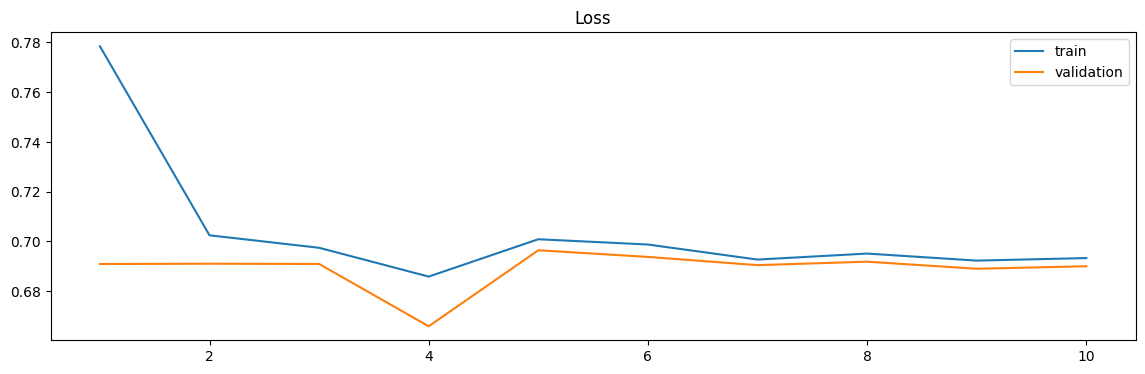

In [31]:
epochs_axis = range(1, len(history["train_loss"]) + 1)

fig, (ax_loss) = plt.subplots(1,1 , figsize=(14, 4))
ax_loss.plot(epochs_axis, history["train_loss"], label="train")
ax_loss.plot(epochs_axis, history["val_loss"], label="validation")
ax_loss.set_title("Loss")
ax_loss.legend()


plt.show()

In [ ]:
evaluate(model, val_loader, device, class_names)